# Lightweight SSL Brain Tumor Classification

**Proposed pipeline:** MRI-aware SimSiam → Stage-wise SE-ResNet18 → Weak-to-Strong Consistency Fine-tuning → Grad-CAM

**Classes:** Glioma, Meningioma, Pituitary, No Tumor

This single notebook is designed for local Jupyter/Anaconda execution on an RTX 3050 8 GB GPU.

## Methodology diagram

```text
   MRI Dataset
        |
        +--> Data audit: corrupt files, exact duplicates, class counts
        |
        +--> Original Training folder --> stratified Train / Validation
        |                                  (Original Testing remains untouched)
        |
        +--> Stage 1: Label-free MRI-aware SimSiam
        |        View-1 --> Shared SE-ResNet18 --> Projector --> Predictor --+
        |        View-2 --> Shared SE-ResNet18 --> Projector --> Predictor --+--> Stop-gradient cosine loss
        |
        +--> Discard projector and predictor
        |
        +--> Stage 2: Four-class fine-tuning
        |        Weak view  --> pretrained SE-ResNet18 --> classifier --+--> Cross-entropy
        |        Strong view--> pretrained SE-ResNet18 --> classifier --+--> consistency loss
        |
        +--> Test metrics + confusion matrix + ROC-AUC + Grad-CAM
```

### Recommended workflow

1. Keep `QUICK_RUN = True` and execute all cells once to detect any errors or missing packages.
2. Set `QUICK_RUN = False`, restart the kernel, and run all cells for the real experiment.
3. For ablation studies, change only the experiment switches in the configuration cell and rerun the notebook.

## 1. Environment setup

Create and activate an Anaconda environment before opening this notebook. First, I installed the CUDA-compatible PyTorch build using the command shown by the official PyTorch installation selector. The cell below installs only the remaining lightweight packages. If it gives a package installation error or a missing package, then just manually install that package the created anaconda environment.

In [1]:
# Run once if these packages are missing, then restart the kernel.
# PyTorch/torchvision should be installed separately using the official CUDA command.

%pip install -q kagglehub numpy pandas scikit-learn matplotlib opencv-python pillow tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports

Importing the necessary libraries for this thesis project.

In [2]:
import os
import gc
import json
import math
import random
import hashlib
import warnings
from pathlib import Path
from contextlib import nullcontext

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    auc,
)
from sklearn.preprocessing import label_binarize

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings('ignore', category=UserWarning)

print('PyTorch:', torch.__version__)
print('Torchvision:', __import__('torchvision').__version__)

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128


## 3. Configuration

For the final proposed method, keep this config for reproducibility:

- `RUN_SSL = True`
- `USE_SE = True`
- `CONSISTENCY_WEIGHT = 0.20`

`NUM_WORKERS=0` is the safest setting for Windows + Jupyter Lab. 

In [3]:
# -------------------------
# Reproducibility and paths
# -------------------------
SEED = 42
QUICK_RUN = False          # First test: True. Final experiment: False.
AUTO_DOWNLOAD = False     # Local dataset is already downloaded.
LOCAL_DATASET_ROOT = Path(r'D:\Thesis\brain-tumor-mri-dataset')
KAGGLE_HANDLE = 'masoudnickparvar/brain-tumor-mri-dataset'

# -------------------------
# Experiment switches
# -------------------------
EXPERIMENT_NAME = 'D_Proposed_SE_SimSiam_WSC'
USE_IMAGENET_INIT = True
RUN_SSL = True
USE_SE = True
CONSISTENCY_WEIGHT = 0.20

# -------------------------
# Data and hardware
# -------------------------
IMAGE_SIZE = 224
VAL_SIZE = 0.15
BATCH_SIZE = 32
NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()
AMP_ENABLED = torch.cuda.is_available()

# -------------------------
# Stage 1: SimSiam
# -------------------------
SSL_EPOCHS = 2 if QUICK_RUN else 50
SSL_LR = 0.005
SSL_MOMENTUM = 0.9
SSL_WEIGHT_DECAY = 1e-4
SSL_WARMUP_EPOCHS = 1 if QUICK_RUN else 5
PROJECTOR_DIM = 1024
PREDICTOR_HIDDEN_DIM = 256

# -------------------------
# Stage 2: Fine-tuning
# -------------------------
HEAD_EPOCHS = 1 if QUICK_RUN else 5
LAYER4_EPOCHS = 1 if QUICK_RUN else 10
FULL_EPOCHS = 1 if QUICK_RUN else 15
DROPOUT = 0.30
EARLY_STOPPING_PATIENCE = 2 if QUICK_RUN else 6

CLASS_NAMES = ['glioma', 'meningioma', 'pituitary', 'notumor']
DISPLAY_NAMES = ['Glioma', 'Meningioma', 'Pituitary', 'No Tumor']
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}

OUTPUT_ROOT = Path('./outputs') / EXPERIMENT_NAME
CHECKPOINT_DIR = OUTPUT_ROOT / 'checkpoints'
FIGURE_DIR = OUTPUT_ROOT / 'figures'
for directory in [OUTPUT_ROOT, CHECKPOINT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

CONFIG = {
    'seed': SEED,
    'quick_run': QUICK_RUN,
    'auto_download': AUTO_DOWNLOAD,
    'local_dataset_root': str(LOCAL_DATASET_ROOT),
    'experiment_name': EXPERIMENT_NAME,
    'use_imagenet_init': USE_IMAGENET_INIT,
    'run_ssl': RUN_SSL,
    'use_se': USE_SE,
    'consistency_weight': CONSISTENCY_WEIGHT,
    'image_size': IMAGE_SIZE,
    'val_size': VAL_SIZE,
    'batch_size': BATCH_SIZE,
    'ssl_epochs': SSL_EPOCHS,
    'head_epochs': HEAD_EPOCHS,
    'layer4_epochs': LAYER4_EPOCHS,
    'full_epochs': FULL_EPOCHS,
}

with open(OUTPUT_ROOT / 'config.json', 'w', encoding='utf-8') as file:
    json.dump(CONFIG, file, indent=2)

CONFIG

{'seed': 42,
 'quick_run': False,
 'auto_download': False,
 'local_dataset_root': 'D:\\Thesis\\brain-tumor-mri-dataset',
 'experiment_name': 'D_Proposed_SE_SimSiam_WSC',
 'use_imagenet_init': True,
 'run_ssl': True,
 'use_se': True,
 'consistency_weight': 0.2,
 'image_size': 224,
 'val_size': 0.15,
 'batch_size': 32,
 'ssl_epochs': 50,
 'head_epochs': 5,
 'layer4_epochs': 10,
 'full_epochs': 15}

## 4. Reproducibility and GPU check

In [4]:
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
    print('CUDA version used by PyTorch:', torch.version.cuda)
    print('GPU memory (GB):', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print('WARNING: CUDA is unavailable. Training will be very slow on CPU.')

Device: cuda
GPU: NVIDIA GeForce RTX 3050
CUDA version used by PyTorch: 12.8
GPU memory (GB): 8.0


## 5. Download or locate the Kaggle dataset

For anyone who wants to download dataset directly from Kaggle. In the config cell, keep AUTO_DOWNLOAD = True. For a public dataset, `kagglehub.dataset_download` usually downloads to a local cache. If authentication is requested, generate a Kaggle token from your Kaggle account settings and run `kagglehub.login()` once.

In [5]:
if AUTO_DOWNLOAD:
    import kagglehub
    try:
        dataset_root = Path(kagglehub.dataset_download(KAGGLE_HANDLE))
    except Exception as exc:
        raise RuntimeError(
            'Automatic Kaggle download failed. Set AUTO_DOWNLOAD=False and '
            'set LOCAL_DATASET_ROOT to the extracted dataset folder.'
        ) from exc
else:
    dataset_root = LOCAL_DATASET_ROOT

if not dataset_root.exists():
    raise FileNotFoundError(f'Dataset root does not exist: {dataset_root.resolve()}')

print('Dataset root:', dataset_root.resolve())

Dataset root: D:\Thesis\brain-tumor-mri-dataset


## 6. Find the Training and Testing directories

In [6]:
def find_directory_case_insensitive(root: Path, candidate_names) -> Path:
    """Find the first directory matching any candidate name, ignoring case."""
    candidate_names = {name.lower() for name in candidate_names}

    # Prefer folders directly inside the dataset root.
    direct_matches = [
        path for path in root.iterdir()
        if path.is_dir() and path.name.lower() in candidate_names
    ]
    if direct_matches:
        direct_matches.sort(key=lambda path: path.name.lower())
        return direct_matches[0]

    # Fallback: search recursively if the dataset has an extra wrapper folder.
    recursive_matches = [
        path for path in root.rglob('*')
        if path.is_dir() and path.name.lower() in candidate_names
    ]
    if not recursive_matches:
        expected = ', '.join(sorted(candidate_names))
        raise FileNotFoundError(
            f'Could not find any of these folders under {root}: {expected}'
        )

    recursive_matches.sort(key=lambda path: len(path.parts))
    return recursive_matches[0]


training_dir = find_directory_case_insensitive(
    dataset_root,
    ['Training', 'Train'],
)
testing_dir = find_directory_case_insensitive(
    dataset_root,
    ['Testing', 'Test'],
)

print('Training directory:', training_dir)
print('Testing directory :', testing_dir)
print('Training class folders:', sorted(path.name for path in training_dir.iterdir() if path.is_dir()))
print('Testing class folders :', sorted(path.name for path in testing_dir.iterdir() if path.is_dir()))


Training directory: D:\Thesis\brain-tumor-mri-dataset\Training
Testing directory : D:\Thesis\brain-tumor-mri-dataset\Testing
Training class folders: ['glioma', 'meningioma', 'notumor', 'pituitary']
Testing class folders : ['glioma', 'meningioma', 'notumor', 'pituitary']


## 7. Build a file-level dataframe

In [7]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
CLASS_ALIASES = {
    'glioma': {'glioma', 'glioma_tumor'},
    'meningioma': {'meningioma', 'meningioma_tumor'},
    'pituitary': {'pituitary', 'pituitary_tumor'},
    'notumor': {'notumor', 'no_tumor', 'no tumor', 'normal'},
}

def canonical_class_name(folder_name: str):
    normalized = folder_name.strip().lower().replace('-', '_')
    for canonical_name, aliases in CLASS_ALIASES.items():
        if normalized in aliases:
            return canonical_name
    return None


def collect_images(split_dir: Path, split_name: str) -> pd.DataFrame:
    records = []
    for class_dir in sorted(path for path in split_dir.iterdir() if path.is_dir()):
        canonical_name = canonical_class_name(class_dir.name)
        if canonical_name is None:
            print(f'Skipping unrecognized folder: {class_dir}')
            continue
        for image_path in class_dir.rglob('*'):
            if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
                records.append({
                    'path': str(image_path),
                    'class_name': canonical_name,
                    'label': CLASS_TO_IDX[canonical_name],
                    'source_split': split_name,
                })
    dataframe = pd.DataFrame(records)
    if dataframe.empty:
        raise RuntimeError(f'No images found under {split_dir}')
    return dataframe

train_full_df = collect_images(training_dir, 'training')
test_df = collect_images(testing_dir, 'testing')

print('Raw training images:', len(train_full_df))
print('Raw testing images :', len(test_df))
display(train_full_df.head())

Raw training images: 5600
Raw testing images : 1600


,path,class_name,label,source_split
0,D:\Thesis\brain-tumor-mri-dataset\Training\gli...,glioma,0,training
1,D:\Thesis\brain-tumor-mri-dataset\Training\gli...,glioma,0,training
2,D:\Thesis\brain-tumor-mri-dataset\Training\gli...,glioma,0,training
3,D:\Thesis\brain-tumor-mri-dataset\Training\gli...,glioma,0,training
4,D:\Thesis\brain-tumor-mri-dataset\Training\gli...,glioma,0,training


## 8. Data audit: class counts and corrupt images

Checking training images:   0%|          | 0/5600 [00:00<?, ?it/s]

Checking testing images:   0%|          | 0/1600 [00:00<?, ?it/s]

Corrupt training images: 0
Corrupt testing images : 0


,Training,Testing
Glioma,1400,400
Meningioma,1400,400
Pituitary,1400,400
No Tumor,1400,400


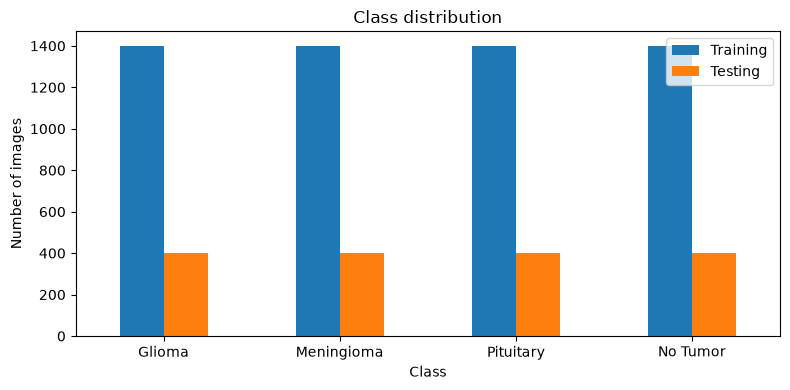

In [8]:
def verify_image(image_path: str):
    try:
        with Image.open(image_path) as image:
            image.verify()
        return True, None
    except Exception as exc:
        return False, str(exc)


def audit_corrupt_images(dataframe: pd.DataFrame, description: str):
    valid_flags = []
    error_messages = []
    for image_path in tqdm(dataframe['path'], desc=f'Checking {description}'):
        is_valid, error = verify_image(image_path)
        valid_flags.append(is_valid)
        error_messages.append(error)
    audited = dataframe.copy()
    audited['is_valid'] = valid_flags
    audited['read_error'] = error_messages
    return audited

train_full_df = audit_corrupt_images(train_full_df, 'training images')
test_df = audit_corrupt_images(test_df, 'testing images')

corrupt_train = train_full_df[~train_full_df['is_valid']]
corrupt_test = test_df[~test_df['is_valid']]
print('Corrupt training images:', len(corrupt_train))
print('Corrupt testing images :', len(corrupt_test))

train_full_df = train_full_df[train_full_df['is_valid']].drop(columns=['is_valid', 'read_error']).reset_index(drop=True)
test_df = test_df[test_df['is_valid']].drop(columns=['is_valid', 'read_error']).reset_index(drop=True)

count_table = pd.concat([
    train_full_df.groupby('class_name').size().rename('Training'),
    test_df.groupby('class_name').size().rename('Testing'),
], axis=1).reindex(CLASS_NAMES)
count_table.index = DISPLAY_NAMES
display(count_table)

ax = count_table.plot(kind='bar', figsize=(8, 4), rot=0)
ax.set_title('Class distribution')
ax.set_xlabel('Class')
ax.set_ylabel('Number of images')
plt.tight_layout()
plt.show()

## 9. Exact duplicate check

This cell computes MD5 hashes. Cross-split duplicates are removed **only from the training pool**, so the original testing images remain the evaluation reference. Exact duplicates inside the training pool are also removed.

In [9]:
def md5_hash(file_path: str, chunk_size=1024 * 1024):
    digest = hashlib.md5()
    with open(file_path, 'rb') as file:
        while chunk := file.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()

for dataframe_name, dataframe in [('training', train_full_df), ('testing', test_df)]:
    if 'md5' not in dataframe.columns:
        dataframe['md5'] = [md5_hash(path) for path in tqdm(dataframe['path'], desc=f'Hashing {dataframe_name}')]

train_duplicate_count = int(train_full_df.duplicated('md5').sum())
test_duplicate_count = int(test_df.duplicated('md5').sum())
cross_split_hashes = set(train_full_df['md5']).intersection(set(test_df['md5']))

print('Exact duplicates inside training:', train_duplicate_count)
print('Exact duplicates inside testing :', test_duplicate_count)
print('Exact hashes shared by train/test:', len(cross_split_hashes))

# Remove conflicting-label hashes from the training pool.
conflicting_train_hashes = (
    train_full_df.groupby('md5')['label'].nunique().loc[lambda series: series > 1].index
)
print('Training hashes with conflicting labels:', len(conflicting_train_hashes))

before_cleanup = len(train_full_df)
train_full_df = train_full_df[~train_full_df['md5'].isin(conflicting_train_hashes)]
train_full_df = train_full_df[~train_full_df['md5'].isin(cross_split_hashes)]
train_full_df = train_full_df.drop_duplicates('md5', keep='first').reset_index(drop=True)
print('Training images removed by duplicate cleanup:', before_cleanup - len(train_full_df))
print('Clean training pool size:', len(train_full_df))

Hashing training:   0%|          | 0/5600 [00:00<?, ?it/s]

Hashing testing:   0%|          | 0/1600 [00:00<?, ?it/s]

Exact duplicates inside training: 171
Exact duplicates inside testing : 16
Exact hashes shared by train/test: 0
Training hashes with conflicting labels: 0
Training images removed by duplicate cleanup: 171
Clean training pool size: 5429


## 10. Stratified train/validation split

Only the original `Training` folder is split. The original `Testing` folder is not used during SSL pretraining, model selection, or hyperparameter tuning.

In [10]:
train_df, val_df = train_test_split(
    train_full_df,
    test_size=VAL_SIZE,
    random_state=SEED,
    stratify=train_full_df['label'],
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

split_summary = pd.DataFrame({
    'Train': train_df.groupby('class_name').size(),
    'Validation': val_df.groupby('class_name').size(),
    'Test': test_df.groupby('class_name').size(),
}).reindex(CLASS_NAMES)
split_summary.index = DISPLAY_NAMES

display(split_summary)
print('Train:', len(train_df), '| Validation:', len(val_df), '| Test:', len(test_df))

train_df.to_csv(OUTPUT_ROOT / 'train_split.csv', index=False)
val_df.to_csv(OUTPUT_ROOT / 'validation_split.csv', index=False)
test_df.to_csv(OUTPUT_ROOT / 'test_split.csv', index=False)

,Train,Validation,Test
Glioma,1190,210,400
Meningioma,1178,208,400
Pituitary,1157,205,400
No Tumor,1089,192,400


Train: 4614 | Validation: 815 | Test: 1600


## 11. MRI preprocessing and augmentations

The black-border crop removes only near-black margins. The model receives three identical channels because ImageNet-pretrained ResNet18 expects three-channel input.

In [11]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def crop_black_border(pil_image: Image.Image, threshold=10) -> Image.Image:
    rgb_image = pil_image.convert('RGB')
    image_array = np.asarray(rgb_image)
    gray = cv2.cvtColor(image_array, cv2.COLOR_RGB2GRAY)
    coordinates = cv2.findNonZero((gray > threshold).astype(np.uint8))
    if coordinates is None:
        return rgb_image
    x, y, width, height = cv2.boundingRect(coordinates)
    return rgb_image.crop((x, y, x + width, y + height))


class AddGaussianNoise:
    def __init__(self, mean=0.0, std=0.01):
        self.mean = mean
        self.std = std

    def __call__(self, tensor):
        noise = torch.randn_like(tensor) * self.std + self.mean
        return torch.clamp(tensor + noise, 0.0, 1.0)


ssl_view_transform = transforms.Compose([
    transforms.Lambda(crop_black_border),
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.80, 1.00),
        ratio=(0.90, 1.10),
        antialias=True,
    ),
    transforms.RandomHorizontalFlip(p=0.50),
    transforms.RandomRotation(degrees=12),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 1.5))], p=0.20),
    transforms.ToTensor(),
    transforms.RandomApply([AddGaussianNoise(std=0.01)], p=0.20),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

weak_transform = transforms.Compose([
    transforms.Lambda(crop_black_border),
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.90, 1.00),
        ratio=(0.95, 1.05),
        antialias=True,
    ),
    transforms.RandomHorizontalFlip(p=0.50),
    transforms.RandomRotation(degrees=7),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

strong_transform = transforms.Compose([
    transforms.Lambda(crop_black_border),
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.80, 1.00),
        ratio=(0.90, 1.10),
        antialias=True,
    ),
    transforms.RandomHorizontalFlip(p=0.50),
    transforms.RandomRotation(degrees=12),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 1.5))], p=0.20),
    transforms.ToTensor(),
    transforms.RandomApply([AddGaussianNoise(std=0.01)], p=0.20),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Lambda(crop_black_border),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

## 12. Dataset classes

In [12]:
class TwoViewMRIDataset(Dataset):
    """Returns two independently augmented views of the same unlabeled MRI."""

    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        image_path = self.dataframe.loc[index, 'path']
        with Image.open(image_path) as image:
            image = image.convert('RGB')
            view_1 = self.transform(image)
            view_2 = self.transform(image)
        return view_1, view_2


class WeakStrongMRIDataset(Dataset):
    """Returns weak and strong views plus the class label."""

    def __init__(self, dataframe, weak_transform, strong_transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.weak_transform = weak_transform
        self.strong_transform = strong_transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.loc[index]
        with Image.open(row['path']) as image:
            image = image.convert('RGB')
            weak_view = self.weak_transform(image)
            strong_view = self.strong_transform(image)
        return weak_view, strong_view, int(row['label'])


class EvaluationMRIDataset(Dataset):
    """Returns a deterministic image, label, and path."""

    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.loc[index]
        with Image.open(row['path']) as image:
            image = image.convert('RGB')
            image_tensor = self.transform(image)
        return image_tensor, int(row['label']), row['path']

## 13. Inspect augmented views

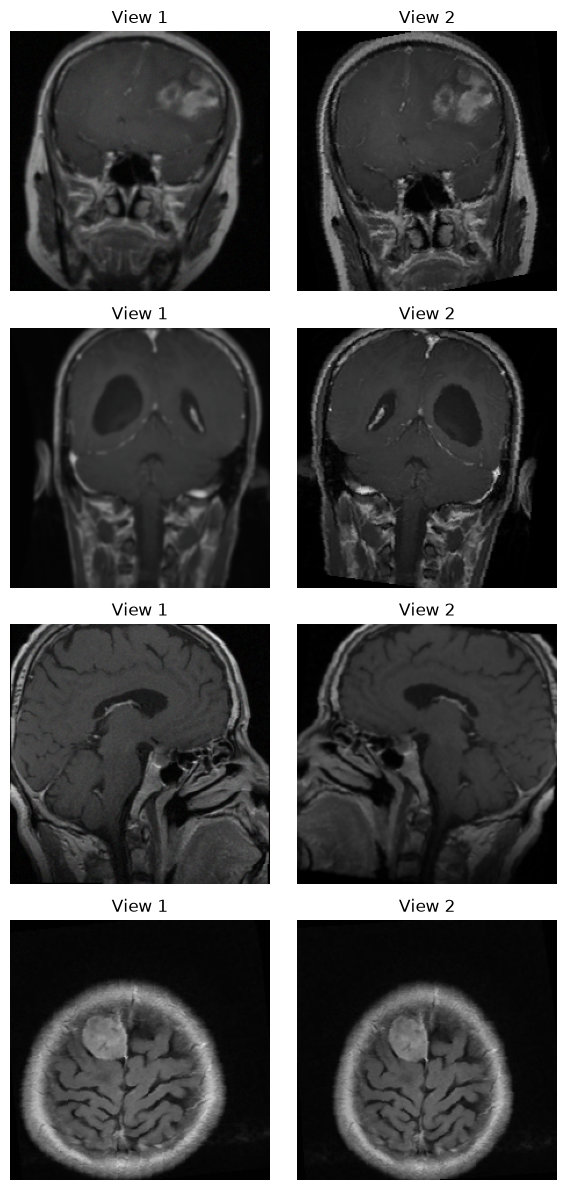

In [13]:
def denormalize_image(tensor):
    mean = torch.tensor(IMAGENET_MEAN, device=tensor.device).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD, device=tensor.device).view(3, 1, 1)
    image = tensor * std + mean
    return image.clamp(0, 1)

preview_dataset = TwoViewMRIDataset(train_df.sample(min(4, len(train_df)), random_state=SEED), ssl_view_transform)
fig, axes = plt.subplots(len(preview_dataset), 2, figsize=(6, 3 * len(preview_dataset)))
if len(preview_dataset) == 1:
    axes = np.array([axes])
for row_index in range(len(preview_dataset)):
    view_1, view_2 = preview_dataset[row_index]
    for column_index, view in enumerate([view_1, view_2]):
        axes[row_index, column_index].imshow(denormalize_image(view).permute(1, 2, 0))
        axes[row_index, column_index].axis('off')
        axes[row_index, column_index].set_title(f'View {column_index + 1}')
plt.tight_layout()
plt.show()

## 14. DataLoaders

In [14]:
def loader_kwargs(shuffle=False, drop_last=False):
    return {
        'batch_size': BATCH_SIZE,
        'shuffle': shuffle,
        'num_workers': NUM_WORKERS,
        'pin_memory': PIN_MEMORY,
        'drop_last': drop_last,
        'persistent_workers': NUM_WORKERS > 0,
    }

ssl_dataset = TwoViewMRIDataset(train_df, ssl_view_transform)
train_supervised_dataset = WeakStrongMRIDataset(train_df, weak_transform, strong_transform)
val_dataset = EvaluationMRIDataset(val_df, eval_transform)
test_dataset = EvaluationMRIDataset(test_df, eval_transform)

ssl_loader = DataLoader(ssl_dataset, **loader_kwargs(shuffle=True, drop_last=True))
train_supervised_loader = DataLoader(train_supervised_dataset, **loader_kwargs(shuffle=True, drop_last=False))
val_loader = DataLoader(val_dataset, **loader_kwargs(shuffle=False, drop_last=False))
test_loader = DataLoader(test_dataset, **loader_kwargs(shuffle=False, drop_last=False))

print('SSL batches:', len(ssl_loader))
print('Supervised training batches:', len(train_supervised_loader))
print('Validation batches:', len(val_loader))
print('Test batches:', len(test_loader))

SSL batches: 144
Supervised training batches: 145
Validation batches: 26
Test batches: 50


## 15. Stage-wise SE-ResNet18 encoder

The SE modules are placed after each ResNet stage rather than inside every residual block. This keeps the implementation small and makes ablation easy.

In [15]:
class SEBlock(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        hidden_channels = max(channels // reduction, 4)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.excitation = nn.Sequential(
            nn.Conv2d(channels, hidden_channels, kernel_size=1, bias=True),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden_channels, channels, kernel_size=1, bias=True),
            nn.Sigmoid(),
        )

    def forward(self, feature_map):
        channel_weights = self.excitation(self.pool(feature_map))
        return feature_map * channel_weights


def create_resnet18(imagenet_init=True):
    weights = ResNet18_Weights.DEFAULT if imagenet_init else None
    try:
        return resnet18(weights=weights)
    except Exception as exc:
        if imagenet_init:
            print('WARNING: ImageNet weights could not be downloaded. Falling back to random initialization.')
            print('Reason:', exc)
            return resnet18(weights=None)
        raise


class SEResNet18Encoder(nn.Module):
    def __init__(self, use_se=True, imagenet_init=True):
        super().__init__()
        backbone = create_resnet18(imagenet_init=imagenet_init)
        self.use_se = use_se
        self.stem = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
        )
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        self.se1 = SEBlock(64) if use_se else nn.Identity()
        self.se2 = SEBlock(128) if use_se else nn.Identity()
        self.se3 = SEBlock(256) if use_se else nn.Identity()
        self.se4 = SEBlock(512) if use_se else nn.Identity()

        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.out_dim = 512

    def forward_feature_map(self, images):
        features = self.stem(images)
        features = self.se1(self.layer1(features))
        features = self.se2(self.layer2(features))
        features = self.se3(self.layer3(features))
        features = self.se4(self.layer4(features))
        return features

    def forward(self, images):
        feature_map = self.forward_feature_map(images)
        features = self.global_pool(feature_map).flatten(1)
        return features


# Shape check
encoder_check = SEResNet18Encoder(use_se=USE_SE, imagenet_init=False).to(device)
with torch.no_grad():
    dummy_features = encoder_check(torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device))
print('Encoder output shape:', tuple(dummy_features.shape))
del encoder_check, dummy_features
gc.collect()
if device.type == 'cuda':
    torch.cuda.empty_cache()

Encoder output shape: (2, 512)


## 16. SimSiam model and loss

In [16]:
class SimSiam(nn.Module):
    def __init__(self, encoder, projector_dim=1024, predictor_hidden_dim=256):
        super().__init__()
        self.encoder = encoder
        feature_dim = encoder.out_dim

        self.projector = nn.Sequential(
            nn.Linear(feature_dim, projector_dim, bias=False),
            nn.BatchNorm1d(projector_dim),
            nn.ReLU(inplace=True),
            nn.Linear(projector_dim, projector_dim, bias=False),
            nn.BatchNorm1d(projector_dim),
            nn.ReLU(inplace=True),
            nn.Linear(projector_dim, projector_dim, bias=False),
            nn.BatchNorm1d(projector_dim, affine=False),
        )

        self.predictor = nn.Sequential(
            nn.Linear(projector_dim, predictor_hidden_dim, bias=False),
            nn.BatchNorm1d(predictor_hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(predictor_hidden_dim, projector_dim),
        )

    def forward(self, view_1, view_2):
        z_1 = self.projector(self.encoder(view_1))
        z_2 = self.projector(self.encoder(view_2))
        p_1 = self.predictor(z_1)
        p_2 = self.predictor(z_2)
        return p_1, p_2, z_1.detach(), z_2.detach()


def negative_cosine_similarity(prediction, target):
    prediction = F.normalize(prediction, dim=1)
    target = F.normalize(target.detach(), dim=1)
    return -(prediction * target).sum(dim=1).mean()


def simsiam_loss(p_1, p_2, z_1, z_2):
    return 0.5 * (
        negative_cosine_similarity(p_1, z_2)
        + negative_cosine_similarity(p_2, z_1)
    )

## 17. AMP and scheduler utilities

In [17]:
def make_grad_scaler(enabled=True):
    try:
        return torch.amp.GradScaler('cuda', enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)


def autocast_context():
    if AMP_ENABLED:
        return torch.autocast(device_type='cuda', dtype=torch.float16, enabled=True)
    return nullcontext()


def warmup_cosine_lambda(current_epoch, total_epochs, warmup_epochs):
    if total_epochs <= 1:
        return 1.0
    if current_epoch < warmup_epochs:
        return float(current_epoch + 1) / max(1, warmup_epochs)
    progress = (current_epoch - warmup_epochs) / max(1, total_epochs - warmup_epochs)
    return 0.5 * (1.0 + math.cos(math.pi * progress))

## 18. SimSiam training functions

In [18]:
def train_simsiam_epoch(model, loader, optimizer, scaler):
    model.train()
    running_loss = 0.0
    running_feature_std = 0.0

    progress_bar = tqdm(loader, desc='SSL training', leave=False)
    for view_1, view_2 in progress_bar:
        view_1 = view_1.to(device, non_blocking=True)
        view_2 = view_2.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            p_1, p_2, z_1, z_2 = model(view_1, view_2)
            loss = simsiam_loss(p_1, p_2, z_1, z_2)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        normalized_features = F.normalize(torch.cat([z_1, z_2], dim=0), dim=1)
        feature_std = normalized_features.std(dim=0).mean().item()
        running_loss += loss.item() * view_1.size(0)
        running_feature_std += feature_std * view_1.size(0)
        progress_bar.set_postfix(loss=f'{loss.item():.4f}', feature_std=f'{feature_std:.4f}')

    sample_count = len(loader.dataset)
    return running_loss / sample_count, running_feature_std / sample_count


def plot_ssl_history(history):
    history_df = pd.DataFrame(history)
    fig, axis = plt.subplots(figsize=(7, 4))
    axis.plot(history_df['epoch'], history_df['ssl_loss'], marker='o')
    axis.set_title('SimSiam pretraining loss')
    axis.set_xlabel('Epoch')
    axis.set_ylabel('Negative cosine loss')
    axis.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    return history_df

## 19. Run SimSiam pretraining

The original testing set is not included. If `RUN_SSL=False`, this section is skipped and the supervised model starts from ImageNet weights.

SSL training:   0%|          | 0/144 [00:00<?, ?it/s]

SSL epoch 01/50 | loss=-0.0085 | feature_std=0.0315 | lr=0.001000


SSL training:   0%|          | 0/144 [00:00<?, ?it/s]

SSL epoch 02/50 | loss=-0.0461 | feature_std=0.0314 | lr=0.002000


SSL training:   0%|          | 0/144 [00:00<?, ?it/s]

...

SSL epoch 48/50 | loss=-0.9473 | feature_std=0.0304 | lr=0.000055


SSL training:   0%|          | 0/144 [00:00<?, ?it/s]

SSL epoch 49/50 | loss=-0.9484 | feature_std=0.0305 | lr=0.000024


SSL training:   0%|          | 0/144 [00:00<?, ?it/s]

SSL epoch 50/50 | loss=-0.9481 | feature_std=0.0305 | lr=0.000006


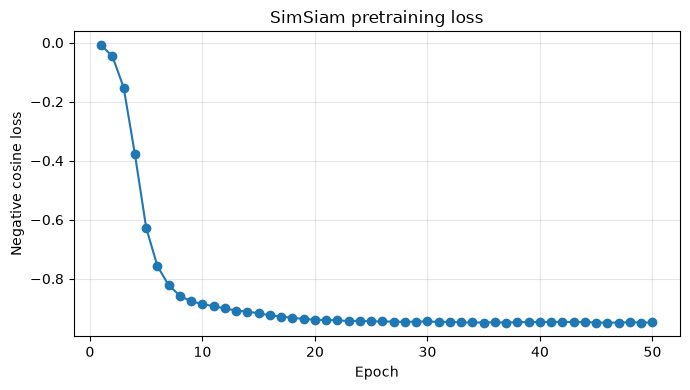

Saved SSL encoder: outputs\D_Proposed_SE_SimSiam_WSC\checkpoints\simsiam_encoder.pth


In [19]:
SSL_ENCODER_PATH = CHECKPOINT_DIR / 'simsiam_encoder.pth'
ssl_history = []

if RUN_SSL:
    ssl_encoder = SEResNet18Encoder(
        use_se=USE_SE,
        imagenet_init=USE_IMAGENET_INIT,
    )
    simsiam_model = SimSiam(
        encoder=ssl_encoder,
        projector_dim=PROJECTOR_DIM,
        predictor_hidden_dim=PREDICTOR_HIDDEN_DIM,
    ).to(device)

    ssl_optimizer = torch.optim.SGD(
        simsiam_model.parameters(),
        lr=SSL_LR,
        momentum=SSL_MOMENTUM,
        weight_decay=SSL_WEIGHT_DECAY,
    )
    ssl_scheduler = torch.optim.lr_scheduler.LambdaLR(
        ssl_optimizer,
        lr_lambda=lambda epoch: warmup_cosine_lambda(
            epoch,
            total_epochs=SSL_EPOCHS,
            warmup_epochs=SSL_WARMUP_EPOCHS,
        ),
    )
    ssl_scaler = make_grad_scaler(enabled=AMP_ENABLED)

    best_ssl_loss = float('inf')
    for epoch in range(1, SSL_EPOCHS + 1):
        epoch_loss, feature_std = train_simsiam_epoch(
            simsiam_model,
            ssl_loader,
            ssl_optimizer,
            ssl_scaler,
        )
        learning_rate = ssl_optimizer.param_groups[0]['lr']
        ssl_history.append({
            'epoch': epoch,
            'ssl_loss': epoch_loss,
            'feature_std': feature_std,
            'learning_rate': learning_rate,
        })
        print(
            f'SSL epoch {epoch:02d}/{SSL_EPOCHS} | '
            f'loss={epoch_loss:.4f} | feature_std={feature_std:.4f} | lr={learning_rate:.6f}'
        )

        if epoch_loss < best_ssl_loss:
            best_ssl_loss = epoch_loss
            torch.save(simsiam_model.encoder.state_dict(), SSL_ENCODER_PATH)

        ssl_scheduler.step()

    ssl_history_df = plot_ssl_history(ssl_history)
    ssl_history_df.to_csv(OUTPUT_ROOT / 'ssl_history.csv', index=False)
    print('Saved SSL encoder:', SSL_ENCODER_PATH)

    del simsiam_model, ssl_encoder, ssl_optimizer, ssl_scheduler, ssl_scaler
    gc.collect()
    if device.type == 'cuda':
        torch.cuda.empty_cache()
else:
    print('RUN_SSL=False: skipping SimSiam pretraining.')

## 20. Classifier and class weights

In [20]:
class BrainTumorClassifier(nn.Module):
    def __init__(self, encoder, num_classes=4, dropout=0.30):
        super().__init__()
        self.encoder = encoder
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(encoder.out_dim, num_classes),
        )

    def forward(self, images):
        features = self.encoder(images)
        return self.classifier(features)


if RUN_SSL:
    classifier_encoder = SEResNet18Encoder(use_se=USE_SE, imagenet_init=False)
    classifier_encoder.load_state_dict(torch.load(SSL_ENCODER_PATH, map_location='cpu'))
    print('Loaded SimSiam-pretrained encoder.')
else:
    classifier_encoder = SEResNet18Encoder(
        use_se=USE_SE,
        imagenet_init=USE_IMAGENET_INIT,
    )
    print('Using ImageNet-initialized encoder without SimSiam.')

classifier_model = BrainTumorClassifier(
    encoder=classifier_encoder,
    num_classes=len(CLASS_NAMES),
    dropout=DROPOUT,
).to(device)

class_counts = train_df['label'].value_counts().sort_index().values.astype(np.float32)
class_weights = len(train_df) / (len(CLASS_NAMES) * class_counts)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

pd.DataFrame({
    'Class': DISPLAY_NAMES,
    'Training samples': class_counts.astype(int),
    'Loss weight': class_weights,
})

Loaded SimSiam-pretrained encoder.


,Class,Training samples,Loss weight
0,Glioma,1190,0.969328
1,Meningioma,1178,0.979202
2,Pituitary,1157,0.996975
3,No Tumor,1089,1.059229


## 21. Fine-tuning utilities

In [21]:
def set_requires_grad(module, trainable):
    for parameter in module.parameters():
        parameter.requires_grad = trainable


def configure_finetuning_phase(model, phase):
    # Freeze everything first.
    set_requires_grad(model.encoder, False)
    set_requires_grad(model.classifier, True)

    if phase == 'head':
        pass
    elif phase == 'layer4':
        set_requires_grad(model.encoder.layer4, True)
        set_requires_grad(model.encoder.se4, True)
    elif phase == 'all':
        set_requires_grad(model.encoder, True)
    else:
        raise ValueError(f'Unknown phase: {phase}')


def enforce_training_modes(model, phase):
    model.train()
    if phase == 'head':
        model.encoder.eval()
    elif phase == 'layer4':
        model.encoder.stem.eval()
        model.encoder.layer1.eval()
        model.encoder.se1.eval()
        model.encoder.layer2.eval()
        model.encoder.se2.eval()
        model.encoder.layer3.eval()
        model.encoder.se3.eval()
        model.encoder.layer4.train()
        model.encoder.se4.train()
    elif phase == 'all':
        model.encoder.train()


def create_finetune_optimizer(model, phase):
    head_parameters = [parameter for parameter in model.classifier.parameters() if parameter.requires_grad]
    parameter_groups = []

    if phase == 'head':
        parameter_groups.append({'params': head_parameters, 'lr': 1e-3})
    elif phase == 'layer4':
        backbone_parameters = [
            parameter for parameter in model.encoder.parameters() if parameter.requires_grad
        ]
        parameter_groups.append({'params': backbone_parameters, 'lr': 1e-4})
        parameter_groups.append({'params': head_parameters, 'lr': 5e-4})
    elif phase == 'all':
        backbone_parameters = [
            parameter for parameter in model.encoder.parameters() if parameter.requires_grad
        ]
        parameter_groups.append({'params': backbone_parameters, 'lr': 1e-5})
        parameter_groups.append({'params': head_parameters, 'lr': 1e-4})

    return torch.optim.AdamW(parameter_groups, weight_decay=1e-4)


def train_classifier_epoch(model, loader, optimizer, scaler, phase):
    enforce_training_modes(model, phase)
    running_loss = 0.0
    all_targets = []
    all_predictions = []

    progress_bar = tqdm(loader, desc=f'Train {phase}', leave=False)
    for weak_images, strong_images, targets in progress_bar:
        weak_images = weak_images.to(device, non_blocking=True)
        strong_images = strong_images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            weak_logits = model(weak_images)
            strong_logits = model(strong_images)

            weak_ce = criterion(weak_logits, targets)
            strong_ce = criterion(strong_logits, targets)

            weak_probabilities = torch.softmax(weak_logits, dim=1).detach()
            strong_log_probabilities = torch.log_softmax(strong_logits, dim=1)
            consistency_loss = F.kl_div(
                strong_log_probabilities,
                weak_probabilities,
                reduction='batchmean',
            )

            loss = weak_ce + 0.5 * strong_ce + CONSISTENCY_WEIGHT * consistency_loss

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        predictions = weak_logits.argmax(dim=1)
        running_loss += loss.item() * targets.size(0)
        all_targets.extend(targets.detach().cpu().numpy())
        all_predictions.extend(predictions.detach().cpu().numpy())
        progress_bar.set_postfix(loss=f'{loss.item():.4f}')

    epoch_loss = running_loss / len(loader.dataset)
    epoch_accuracy = accuracy_score(all_targets, all_predictions)
    _, _, epoch_f1, _ = precision_recall_fscore_support(
        all_targets,
        all_predictions,
        average='macro',
        zero_division=0,
    )
    return epoch_loss, epoch_accuracy, epoch_f1


@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    running_loss = 0.0
    all_targets = []
    all_predictions = []
    all_probabilities = []
    all_paths = []

    for images, targets, paths in tqdm(loader, desc='Evaluating', leave=False):
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        with autocast_context():
            logits = model(images)
            loss = criterion(logits, targets)
        probabilities = torch.softmax(logits.float(), dim=1)
        predictions = probabilities.argmax(dim=1)

        running_loss += loss.item() * targets.size(0)
        all_targets.extend(targets.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())
        all_paths.extend(paths)

    targets_array = np.asarray(all_targets)
    predictions_array = np.asarray(all_predictions)
    probabilities_array = np.asarray(all_probabilities)

    accuracy = accuracy_score(targets_array, predictions_array)
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        targets_array,
        predictions_array,
        average='macro',
        zero_division=0,
    )

    return {
        'loss': running_loss / len(loader.dataset),
        'accuracy': accuracy,
        'macro_precision': precision,
        'macro_recall': recall,
        'macro_f1': macro_f1,
        'targets': targets_array,
        'predictions': predictions_array,
        'probabilities': probabilities_array,
        'paths': all_paths,
    }

## 22. Progressive fine-tuning

The best checkpoint is selected using validation macro-F1. It will be saved in the output folder for inference.

In [22]:
BEST_CLASSIFIER_PATH = CHECKPOINT_DIR / 'best_classifier.pth'
finetune_history = []
best_validation_f1 = -1.0

phase_plan = [
    {'name': 'head', 'epochs': HEAD_EPOCHS},
    {'name': 'layer4', 'epochs': LAYER4_EPOCHS},
    {'name': 'all', 'epochs': FULL_EPOCHS},
]

for phase_configuration in phase_plan:
    phase_name = phase_configuration['name']
    phase_epochs = phase_configuration['epochs']
    configure_finetuning_phase(classifier_model, phase_name)
    optimizer = create_finetune_optimizer(classifier_model, phase_name)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, phase_epochs))
    scaler = make_grad_scaler(enabled=AMP_ENABLED)
    epochs_without_improvement = 0

    print(f'\nStarting phase: {phase_name} ({phase_epochs} epochs)')
    for local_epoch in range(1, phase_epochs + 1):
        train_loss, train_accuracy, train_f1 = train_classifier_epoch(
            classifier_model,
            train_supervised_loader,
            optimizer,
            scaler,
            phase_name,
        )
        validation_result = evaluate_classifier(classifier_model, val_loader)

        record = {
            'phase': phase_name,
            'epoch_in_phase': local_epoch,
            'train_loss': train_loss,
            'train_accuracy': train_accuracy,
            'train_macro_f1': train_f1,
            'val_loss': validation_result['loss'],
            'val_accuracy': validation_result['accuracy'],
            'val_macro_f1': validation_result['macro_f1'],
            'learning_rates': [group['lr'] for group in optimizer.param_groups],
        }
        finetune_history.append(record)

        print(
            f'{phase_name} {local_epoch:02d}/{phase_epochs} | '
            f'train loss={train_loss:.4f}, F1={train_f1:.4f} | '
            f'val loss={validation_result["loss"]:.4f}, '
            f'accuracy={validation_result["accuracy"]:.4f}, '
            f'F1={validation_result["macro_f1"]:.4f}'
        )

        if validation_result['macro_f1'] > best_validation_f1:
            best_validation_f1 = validation_result['macro_f1']
            epochs_without_improvement = 0
            torch.save({
                'model_state_dict': classifier_model.state_dict(),
                'best_validation_macro_f1': best_validation_f1,
                'class_names': CLASS_NAMES,
                'config': CONFIG,
            }, BEST_CLASSIFIER_PATH)
        else:
            epochs_without_improvement += 1

        scheduler.step()

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(f'Early stopping phase {phase_name}.')
            break

finetune_history_df = pd.DataFrame(finetune_history)
finetune_history_df.to_csv(OUTPUT_ROOT / 'finetune_history.csv', index=False)
print('\nBest validation macro-F1:', round(best_validation_f1, 4))
print('Saved classifier:', BEST_CLASSIFIER_PATH)


Starting phase: head (5 epochs)


Train head:   0%|          | 0/145 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/26 [00:00<?, ?it/s]

head 01/5 | train loss=1.1095, F1=0.7275 | val loss=0.5640, accuracy=0.8123, F1=0.8147


Train head:   0%|          | 0/145 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/26 [00:00<?, ?it/s]

all 09/15 | train loss=0.0138, F1=0.9987 | val loss=0.0557, accuracy=0.9840, F1=0.9841


Train all:   0%|          | 0/145 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/26 [00:00<?, ?it/s]

all 10/15 | train loss=0.0125, F1=0.9985 | val loss=0.0511, accuracy=0.9853, F1=0.9853
Early stopping phase all.

Best validation macro-F1: 0.9901
Saved classifier: outputs\D_Proposed_SE_SimSiam_WSC\checkpoints\best_classifier.pth


## 23. Plot fine-tuning history

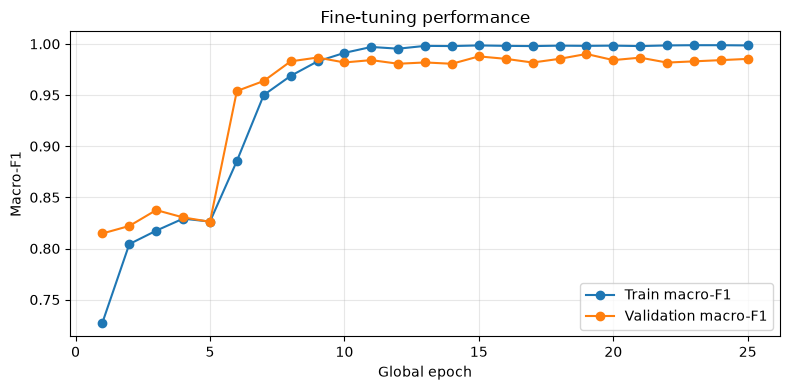

In [23]:
history_plot_df = finetune_history_df.copy()
history_plot_df['global_epoch'] = np.arange(1, len(history_plot_df) + 1)

fig, axis = plt.subplots(figsize=(8, 4))
axis.plot(history_plot_df['global_epoch'], history_plot_df['train_macro_f1'], marker='o', label='Train macro-F1')
axis.plot(history_plot_df['global_epoch'], history_plot_df['val_macro_f1'], marker='o', label='Validation macro-F1')
axis.set_title('Fine-tuning performance')
axis.set_xlabel('Global epoch')
axis.set_ylabel('Macro-F1')
axis.legend()
axis.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'finetuning_macro_f1.png', dpi=200, bbox_inches='tight')
plt.show()

## 24. Load the best model and evaluate on the untouched test set

In [24]:
checkpoint = torch.load(BEST_CLASSIFIER_PATH, map_location=device)
classifier_model.load_state_dict(checkpoint['model_state_dict'])
classifier_model.eval()
print('Loaded checkpoint with validation macro-F1:', checkpoint['best_validation_macro_f1'])

test_result = evaluate_classifier(classifier_model, test_loader)

summary_metrics = {
    'experiment': EXPERIMENT_NAME,
    'accuracy': test_result['accuracy'],
    'macro_precision': test_result['macro_precision'],
    'macro_recall': test_result['macro_recall'],
    'macro_f1': test_result['macro_f1'],
}
summary_metrics_df = pd.DataFrame([summary_metrics])
display(summary_metrics_df)
summary_metrics_df.to_csv(OUTPUT_ROOT / 'test_summary_metrics.csv', index=False)

Loaded checkpoint with validation macro-F1: 0.9901464088507358


Evaluating:   0%|          | 0/50 [00:00<?, ?it/s]

,experiment,accuracy,macro_precision,macro_recall,macro_f1
0,D_Proposed_SE_SimSiam_WSC,0.955625,0.958167,0.955625,0.954873


## 25. Classification report

In [25]:
report_dictionary = classification_report(
    test_result['targets'],
    test_result['predictions'],
    labels=list(range(len(CLASS_NAMES))),
    target_names=DISPLAY_NAMES,
    output_dict=True,
    zero_division=0,
)
classification_report_df = pd.DataFrame(report_dictionary).T
classification_report_df.to_csv(OUTPUT_ROOT / 'classification_report.csv')
display(classification_report_df.round(4))

,precision,recall,f1-score,support
Glioma,0.9941,0.8475,0.9150,400.0000
Meningioma,0.9053,0.9800,0.9412,400.0000
Pituitary,0.9876,0.9950,0.9913,400.0000
No Tumor,0.9456,1.0000,0.9721,400.0000
accuracy,0.9556,0.9556,0.9556,0.9556
macro avg,0.9582,0.9556,0.9549,1600.0000
weighted avg,0.9582,0.9556,0.9549,1600.0000


## 26. Confusion matrix

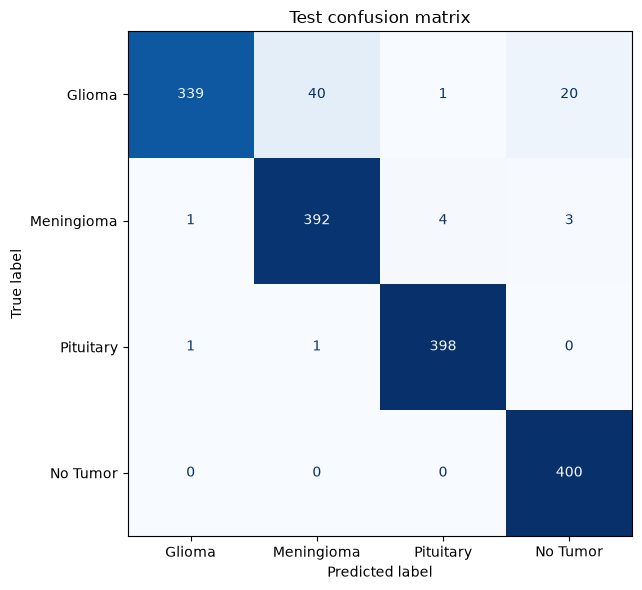

In [26]:
confusion = confusion_matrix(
    test_result['targets'],
    test_result['predictions'],
    labels=list(range(len(CLASS_NAMES))),
)

fig, axis = plt.subplots(figsize=(7, 6))
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=DISPLAY_NAMES,
)
display_matrix.plot(ax=axis, cmap='Blues', values_format='d', colorbar=False)
axis.set_title('Test confusion matrix')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

## 27. One-vs-rest ROC-AUC curves

Macro one-vs-rest ROC-AUC: 0.988


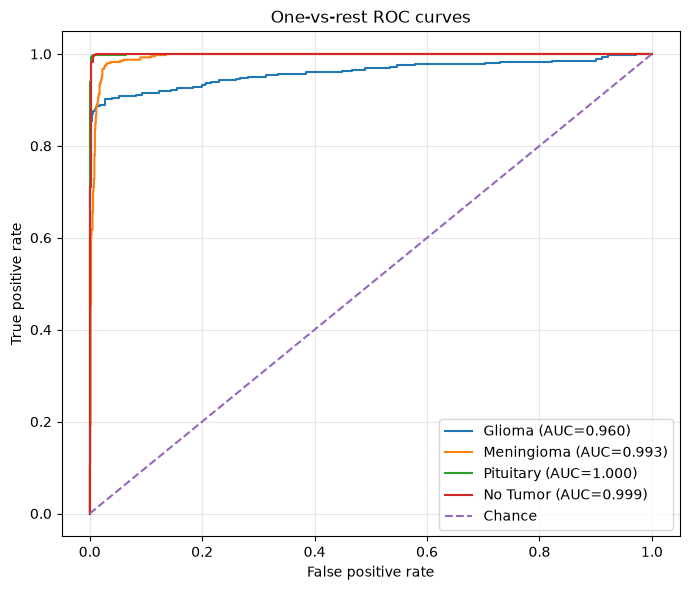

In [27]:
binarized_targets = label_binarize(
    test_result['targets'],
    classes=list(range(len(CLASS_NAMES))),
)

try:
    macro_auc = roc_auc_score(
        binarized_targets,
        test_result['probabilities'],
        average='macro',
        multi_class='ovr',
    )
    print('Macro one-vs-rest ROC-AUC:', round(macro_auc, 4))
except ValueError as exc:
    macro_auc = np.nan
    print('ROC-AUC could not be calculated:', exc)

fig, axis = plt.subplots(figsize=(7, 6))
for class_index, display_name in enumerate(DISPLAY_NAMES):
    false_positive_rate, true_positive_rate, _ = roc_curve(
        binarized_targets[:, class_index],
        test_result['probabilities'][:, class_index],
    )
    class_auc = auc(false_positive_rate, true_positive_rate)
    axis.plot(false_positive_rate, true_positive_rate, label=f'{display_name} (AUC={class_auc:.3f})')

axis.plot([0, 1], [0, 1], linestyle='--', label='Chance')
axis.set_title('One-vs-rest ROC curves')
axis.set_xlabel('False positive rate')
axis.set_ylabel('True positive rate')
axis.legend(loc='lower right')
axis.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'roc_curves.png', dpi=200, bbox_inches='tight')
plt.show()

summary_metrics_df['macro_ovr_auc'] = macro_auc
summary_metrics_df.to_csv(OUTPUT_ROOT / 'test_summary_metrics.csv', index=False)

## 28. Save per-image test predictions

In [28]:
prediction_table = pd.DataFrame({
    'path': test_result['paths'],
    'true_label': [DISPLAY_NAMES[index] for index in test_result['targets']],
    'predicted_label': [DISPLAY_NAMES[index] for index in test_result['predictions']],
    'correct': test_result['targets'] == test_result['predictions'],
})
for class_index, display_name in enumerate(DISPLAY_NAMES):
    prediction_table[f'prob_{CLASS_NAMES[class_index]}'] = test_result['probabilities'][:, class_index]

prediction_table.to_csv(OUTPUT_ROOT / 'test_predictions.csv', index=False)
display(prediction_table.head())
print('Incorrect predictions:', int((~prediction_table['correct']).sum()))

,path,true_label,predicted_label,correct,prob_glioma,prob_meningioma,prob_pituitary,prob_notumor
0,D:\Thesis\brain-tumor-mri-dataset\Testing\glio...,Glioma,Meningioma,False,0.481129,0.502989,0.008997,0.006885
1,D:\Thesis\brain-tumor-mri-dataset\Testing\glio...,Glioma,Glioma,True,0.999716,0.000203,0.000007,0.000074
2,D:\Thesis\brain-tumor-mri-dataset\Testing\glio...,Glioma,Glioma,True,0.999969,0.000014,0.000002,0.000015
3,D:\Thesis\brain-tumor-mri-dataset\Testing\glio...,Glioma,Glioma,True,0.998111,0.001864,0.000024,0.000002
4,D:\Thesis\brain-tumor-mri-dataset\Testing\glio...,Glioma,Glioma,True,0.987371,0.002085,0.004221,0.006323


Incorrect predictions: 71


## 29. Manual Grad-CAM implementation

The target layer is the final convolution of the last ResNet18 residual block. Grad-CAM is used for model interpretation, not as a tumor segmentation ground truth.

In [29]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.forward_handle = target_layer.register_forward_hook(self._forward_hook)
        self.backward_handle = target_layer.register_full_backward_hook(self._backward_hook)

    def _forward_hook(self, module, inputs, output):
        self.activations = output.detach()

    def _backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_index=None):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)
        logits = self.model(input_tensor)
        if class_index is None:
            class_index = int(logits.argmax(dim=1).item())
        score = logits[:, class_index].sum()
        score.backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = F.interpolate(
            cam,
            size=input_tensor.shape[-2:],
            mode='bilinear',
            align_corners=False,
        )
        cam = cam.squeeze()
        cam_min, cam_max = cam.min(), cam.max()
        cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)
        return cam.cpu().numpy(), logits.detach()

    def close(self):
        self.forward_handle.remove()
        self.backward_handle.remove()


def make_gradcam_overlay(normalized_tensor, heatmap, alpha=0.40):
    image = denormalize_image(normalized_tensor.cpu()).permute(1, 2, 0).numpy()
    heatmap_uint8 = np.uint8(255 * heatmap)
    colored_heatmap = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    colored_heatmap = cv2.cvtColor(colored_heatmap, cv2.COLOR_BGR2RGB) / 255.0
    overlay = np.clip((1 - alpha) * image + alpha * colored_heatmap, 0, 1)
    return image, colored_heatmap, overlay

## 30. Display Grad-CAM examples

The cell first attempts to show one correct example per class and then several incorrect examples.

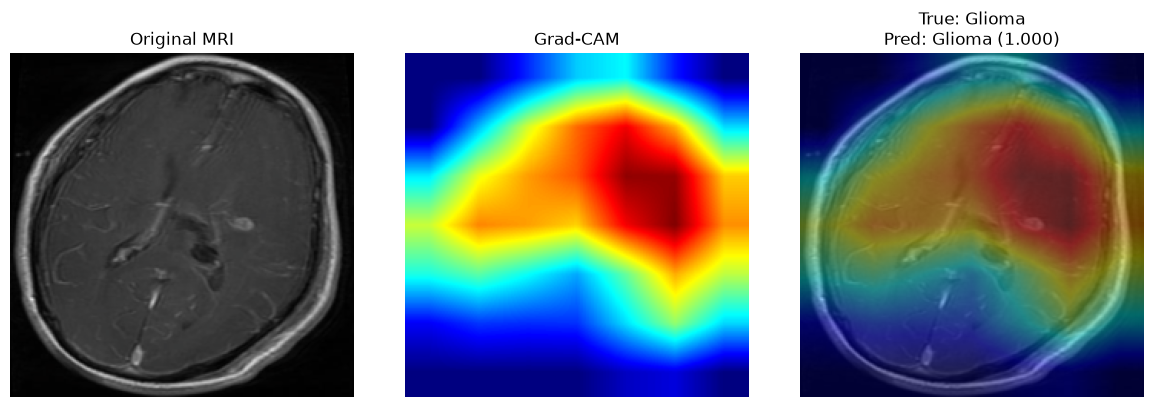

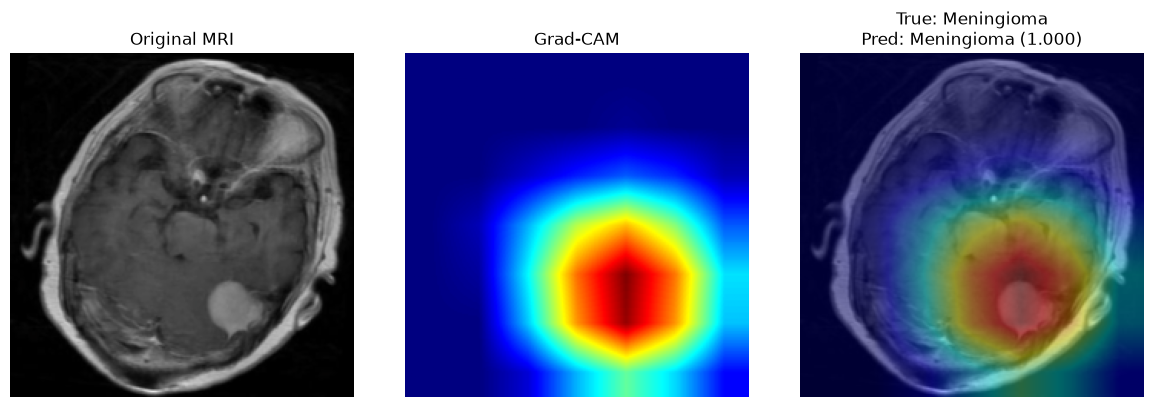

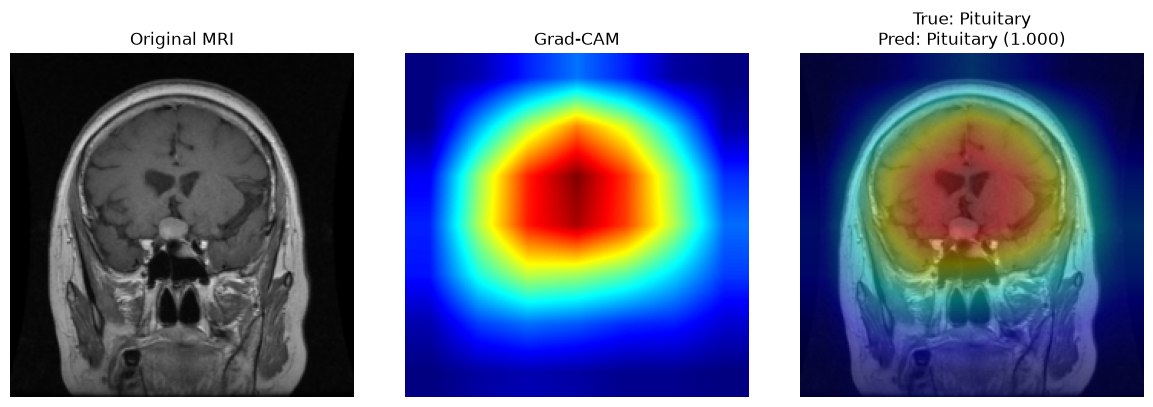

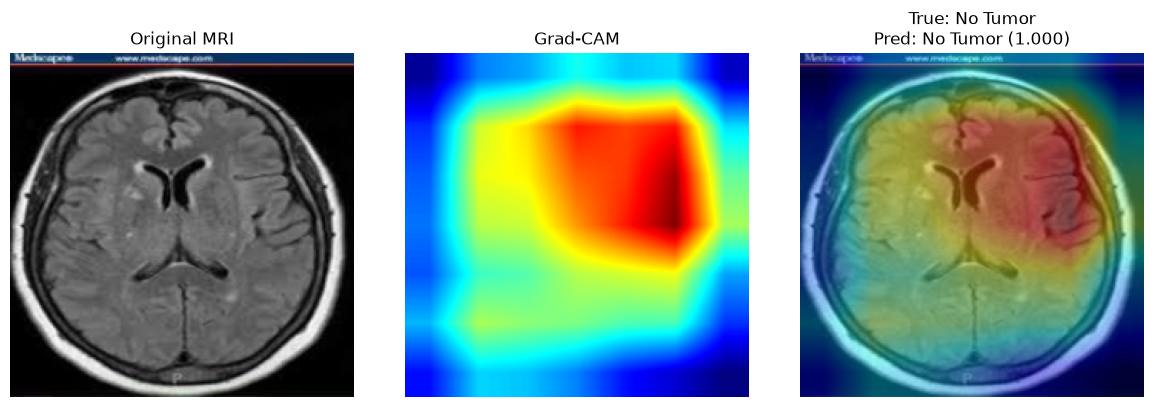

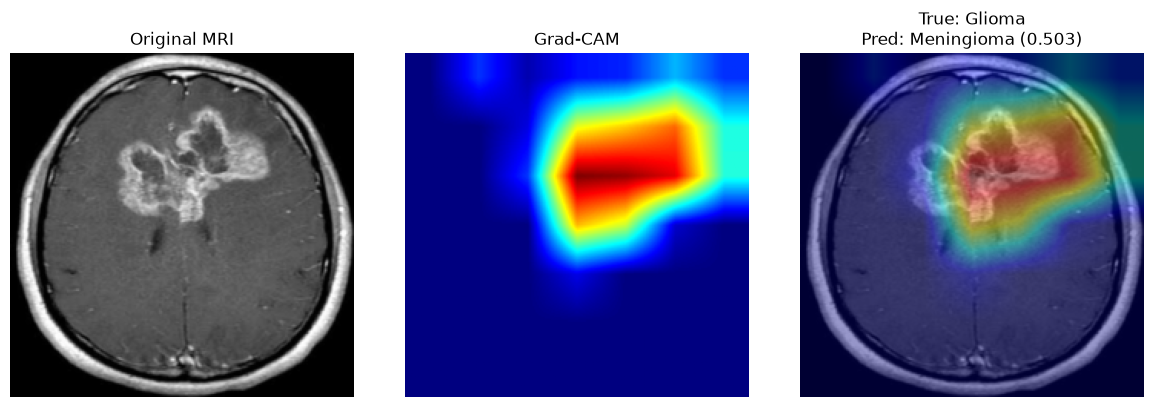

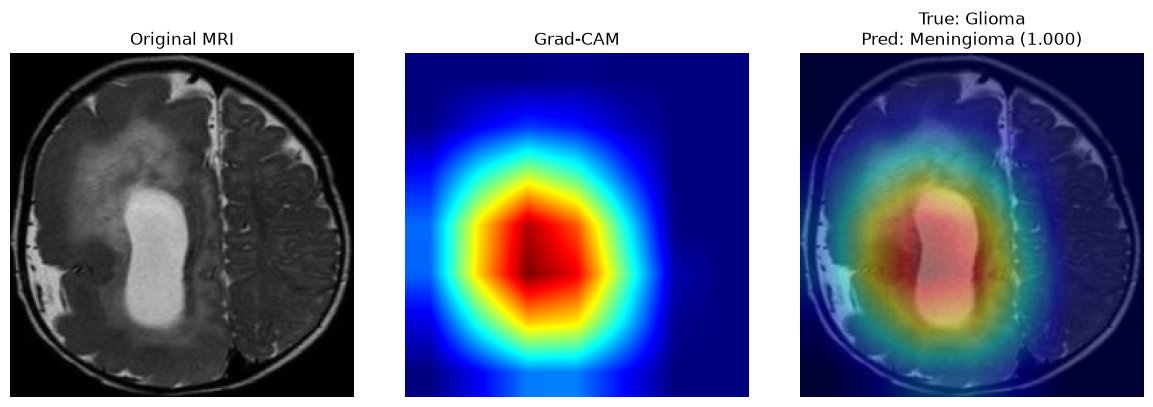

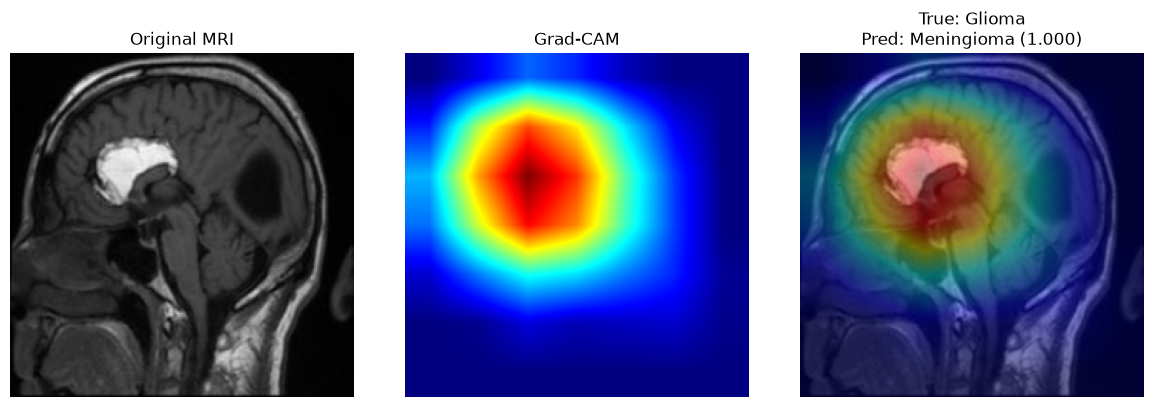

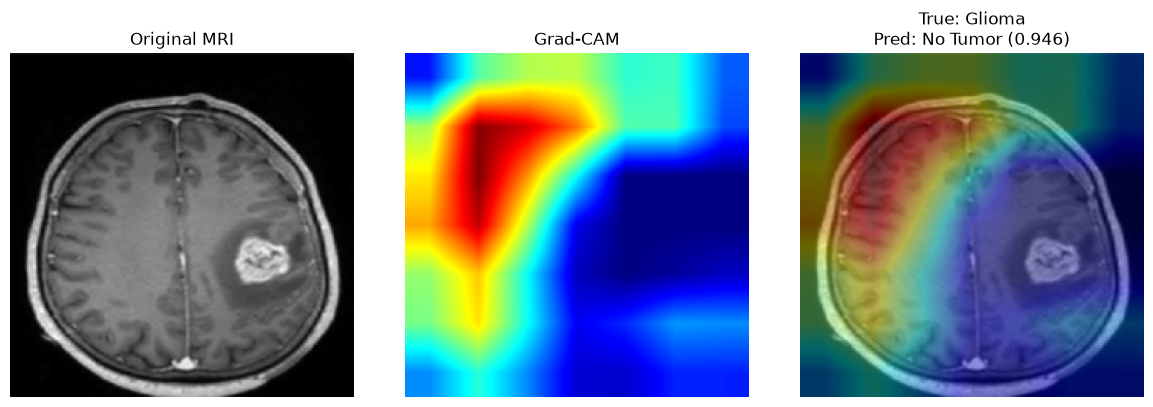

In [30]:
gradcam = GradCAM(
    classifier_model,
    target_layer=classifier_model.encoder.layer4[-1].conv2,
)

correct_indices = []
for class_index in range(len(CLASS_NAMES)):
    matching = prediction_table.index[
        (prediction_table['correct'])
        & (prediction_table['true_label'] == DISPLAY_NAMES[class_index])
    ].tolist()
    if matching:
        correct_indices.append(matching[0])

incorrect_indices = prediction_table.index[~prediction_table['correct']].tolist()[:4]
selected_indices = correct_indices + incorrect_indices

if not selected_indices:
    print('No examples available for Grad-CAM.')
else:
    for dataframe_index in selected_indices:
        image_tensor, true_index, image_path = test_dataset[dataframe_index]
        input_tensor = image_tensor.unsqueeze(0).to(device)
        heatmap, logits = gradcam.generate(input_tensor)
        probabilities = torch.softmax(logits.float(), dim=1).cpu().numpy()[0]
        predicted_index = int(probabilities.argmax())
        original, colored_heatmap, overlay = make_gradcam_overlay(image_tensor, heatmap)

        fig, axes = plt.subplots(1, 3, figsize=(12, 4))
        axes[0].imshow(original)
        axes[0].set_title('Original MRI')
        axes[1].imshow(colored_heatmap)
        axes[1].set_title('Grad-CAM')
        axes[2].imshow(overlay)
        axes[2].set_title(
            f'True: {DISPLAY_NAMES[true_index]}\n'
            f'Pred: {DISPLAY_NAMES[predicted_index]} ({probabilities[predicted_index]:.3f})'
        )
        for axis in axes:
            axis.axis('off')
        plt.tight_layout()
        output_name = f'gradcam_{dataframe_index}_{CLASS_NAMES[true_index]}_to_{CLASS_NAMES[predicted_index]}.png'
        plt.savefig(FIGURE_DIR / output_name, dpi=200, bbox_inches='tight')
        plt.show()

gradcam.close()

## 31. Single-image inference helper

In [31]:
@torch.no_grad()
def predict_single_image(model, image_path):
    with Image.open(image_path) as image:
        image = image.convert('RGB')
        image_tensor = eval_transform(image).unsqueeze(0).to(device)
    model.eval()
    logits = model(image_tensor)
    probabilities = torch.softmax(logits.float(), dim=1).cpu().numpy()[0]
    predicted_index = int(probabilities.argmax())
    result = pd.DataFrame({
        'Class': DISPLAY_NAMES,
        'Probability': probabilities,
    }).sort_values('Probability', ascending=False)
    return DISPLAY_NAMES[predicted_index], result

# Example:
# predicted_class, probabilities = predict_single_image(classifier_model, r'path/to/an/MRI.jpg')
# print('Prediction:', predicted_class)
# display(probabilities)

## 32. Ablation study plan

Change the configuration switches at the top, restart the kernel, and run all cells for each experiment.

In [32]:
ablation_plan = pd.DataFrame([
    {
        'Experiment': 'A_Supervised_ResNet18',
        'RUN_SSL': False,
        'USE_SE': False,
        'CONSISTENCY_WEIGHT': 0.0,
    },
    {
        'Experiment': 'B_SimSiam_ResNet18',
        'RUN_SSL': True,
        'USE_SE': False,
        'CONSISTENCY_WEIGHT': 0.0,
    },
    {
        'Experiment': 'C_SE_SimSiam',
        'RUN_SSL': True,
        'USE_SE': True,
        'CONSISTENCY_WEIGHT': 0.0,
    },
    {
        'Experiment': 'D_Proposed_SE_SimSiam_WSC',
        'RUN_SSL': True,
        'USE_SE': True,
        'CONSISTENCY_WEIGHT': 0.20,
    },
])
display(ablation_plan)

,Experiment,RUN_SSL,USE_SE,CONSISTENCY_WEIGHT
0,A_Supervised_ResNet18,False,False,0.0
1,B_SimSiam_ResNet18,True,False,0.0
2,C_SE_SimSiam,True,True,0.0
3,D_Proposed_SE_SimSiam_WSC,True,True,0.2


## 33. Combine completed ablation results

Run this cell after all experiment folders exist under `./outputs/`.

In [33]:
result_files = sorted(Path('./outputs').glob('*/test_summary_metrics.csv'))
completed_results = []
for result_file in result_files:
    result_dataframe = pd.read_csv(result_file)
    result_dataframe['result_file'] = str(result_file)
    completed_results.append(result_dataframe)

if completed_results:
    ablation_results_df = pd.concat(completed_results, ignore_index=True)
    display(ablation_results_df.sort_values('macro_f1', ascending=False))
    ablation_results_df.to_csv('./outputs/ablation_results.csv', index=False)
else:
    print('No completed experiment result files found yet.')

,experiment,accuracy,macro_precision,macro_recall,macro_f1,macro_ovr_auc,result_file
0,D_Proposed_SE_SimSiam_WSC,0.955625,0.958167,0.955625,0.954873,0.987984,outputs\D_Proposed_SE_SimSiam_WSC\test_summary...


## End of the Implementation